In [1]:
import numpy as np
import matplotlib.pyplot as plt
# import segmentation_models_pytorch as smp

from gUnet import Unet2D

In [2]:
simsNP = np.load("data/sample_16_19_fixwin_sims.npy")
maskNP = np.load("data/sample_16_19_fixwin_mask.npy")
dayNP = np.load("data/sample_16_19_fixwin_day.npy")
hourNP = np.load("data/sample_16_19_fixwin_hour.npy")

print(dayNP.shape)

(5000,)


In [3]:
keep = np.all(maskNP == 0, axis=(1,2))
maskNP = maskNP[keep]
simsNP = simsNP[keep]
dayNp = dayNP[keep]
hourNP = hourNP[keep]


In [4]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from datetime import datetime

# ----------------------------
# Dataset
# ----------------------------
class SimulationDataset(Dataset):
    """
    Expects data of shape [T, 3, H, W] — a time series of simulation snapshots.
    Returns (input: [9, H, W], target: [3, H, W]) pairs.
    """
    def __init__(self, data: torch.Tensor, mask: torch.Tensor, day:torch.Tensor, hour:torch.Tensor, mean=None, std=None, iD=3):
        self.iD = iD # input dim
        # data: [N, 7, 3, H, W]
        self.x = torch.cat([
            data[:, 0, :iD, :, :],   # [N, 3, H, W]
            data[:, 1, :iD, :, :],   # [N, 3, H, W]
            data[:, 2, :iD, :, :],   # [N, 3, H, W]
            data[:, 3, :iD, :, :],   # [N, 3, H, W]
        ], dim=1).float()                  # [N, 9, H, W]

        #self.y = (data[:, 4, :, :, :] - data[:, 3, :, :, :]).float()   # [N, 3, H, W]
        self.y = torch.cat([
            (data[:, 4, :iD, :, :] - data[:, 3, :iD, :, :]),   # [N, 3, H, W]
            (data[:, 5, :iD, :, :] - data[:, 4, :iD, :, :]),   # [N, 3, H, W]
            (data[:, 6, :iD, :, :] - data[:, 5, :iD, :, :]),   # [N, 3, H, W]
        ], dim=1).float() 

        self.mask = mask  # [N, H, W]

        # Compute stats from this data if not provided (i.e. training set)
        if mean is None:
            # mean/std over N, H, W — keep channel dim → shape [1, 9, 1, 1]
            self.mean = (
                data[:, 0,:iD].float().mean(dim=(0, 2, 3), keepdim=True) +
                data[:, 1,:iD].float().mean(dim=(0, 2, 3), keepdim=True) +
                data[:, 2,:iD].float().mean(dim=(0, 2, 3), keepdim=True) + 
                data[:, 3,:iD].float().mean(dim=(0, 2, 3), keepdim=True)
            ) / 4.0   
            # For std, pool all timesteps together for a more stable estimate
            self.std = torch.cat([
                data[:, 0,:iD].float(),
                data[:, 1,:iD].float(),
                data[:, 2,:iD].float(),
                data[:, 3,:iD].float(),                
            ], dim=0).std(dim=(0, 2, 3), keepdim=True)  # [1, 4, 1, 1]            

        else:
            self.mean = mean
            self.std  = std


        mean_x = self.mean.repeat(1, 4, 1, 1)  # [1, 9, 1, 1]
        std_x  = self.std.repeat(1, 4, 1, 1)   # [1, 9, 1, 1]

        std_y  = self.std.repeat(1, 3, 1, 1)   # [1, 9, 1, 1]
        # Normalize x
        self.x = (self.x - mean_x) / (std_x + 1e-8)        

        # Normalize y using only the first 3 channels stats (single timestep)
        self.y = self.y  / (std_y + 1e-8)

        #print(self.mean,self.std,"Delta ",self.y.min()-self.y.max(),self.x.min()-self.x.max())


        self.day = day.float()/365
        self.hour = hour.float()/365

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx], self.mask[idx],self.day[idx],self.hour[idx]  # [9, H, W], [3, H, W], [H, W]


####################################################################
import torch
import torch.nn.functional as F


def spectral_loss(pred, target, eps=1e-8):
    """
    pred,target:
        [B,C,H,W]

    Computes spectral amplitude loss.
    """

    # FFT
    pred_fft = torch.fft.rfft2(pred)
    targ_fft = torch.fft.rfft2(target)

    # Amplitude spectra
    pred_amp = torch.abs(pred_fft)
    targ_amp = torch.abs(targ_fft)

    # Linear spectrum loss
    loss_amp = F.l1_loss(pred_amp, targ_amp)

    # Log spectrum loss
    loss_log = F.l1_loss(
        torch.log(pred_amp + eps),
        torch.log(targ_amp + eps)
    )

    return loss_amp + loss_log
####################################################################
def masked_relative_l2_loss(pred, target, mask, eps=1e-8):
    """
    Relative/scaled L2 loss.

    Computes:

        ||pred - target||_2 / ||target||_2

    only on valid pixels where mask == 0.

    pred:   [B, C, H, W]
    target: [B, C, H, W]
    mask:   [B, H, W]
    """

    # valid pixels
    valid = (mask == 0).unsqueeze(1).expand_as(pred)

    # apply mask
    pred_valid = pred * valid
    target_valid = target * valid

    # flatten per sample
    pred_valid = pred_valid.reshape(pred.shape[0], -1)
    target_valid = target_valid.reshape(target.shape[0], -1)

    # numerator: ||pred-target||_2
    num = torch.norm(pred_valid - target_valid, p=2, dim=1)

    # denominator: ||target||_2
    den = torch.norm(target_valid, p=2, dim=1) + eps

    # relative error per sample
    loss = num / den

    return loss.mean()
####################################################################
def masked_loss(pred, target, mask):
    """Only compute loss on pixels where mask == 0."""
    # mask: [B, H, W] → expand to [B, 3, H, W]
    valid = (mask == 0).unsqueeze(1).expand_as(pred)
    # return nn.functional.mse_loss(pred[valid], target[valid])
    return nn.functional.l1_loss(pred[valid], target[valid])
####################################################################
def create_spatial_weight(h=128, w=128, sigma=32):

    y = torch.arange(h).float()
    x = torch.arange(w).float()

    yy, xx = torch.meshgrid(y, x, indexing='ij')

    cy = (h - 1) / 2
    cx = (w - 1) / 2

    dist2 = (yy - cy) ** 2 + (xx - cx) ** 2

    weight = torch.exp(-dist2 / (2 * sigma ** 2))

    # normalize so mean weight ≈ 1
    weight = weight / weight.mean()

    return weight
####################################################################
def weighted_charbonnier_loss(
    pred,
    target,
    mask,
    spatial_weight,
    eps=1e-3,
):

    valid = (mask == 0).unsqueeze(1)

    # [1,1,H,W]
    spatial_weight = spatial_weight.to(pred.device)
    spatial_weight = spatial_weight.unsqueeze(0).unsqueeze(0)

    diff = pred - target

    loss = torch.sqrt(diff * diff + eps * eps)

    # apply:
    # - validity mask
    # - spatial weighting
    weighted_loss = loss * valid * spatial_weight

    return weighted_loss.sum() / (valid * spatial_weight).sum()
####################################################################
def gradient_loss(pred, target):

    dx_p = pred[:, :, :, 1:] - pred[:, :, :, :-1]
    dy_p = pred[:, :, 1:, :] - pred[:, :, :-1, :]

    dx_t = target[:, :, :, 1:] - target[:, :, :, :-1]
    dy_t = target[:, :, 1:, :] - target[:, :, :-1, :]

    return (
        nn.functional.l1_loss(dx_p, dx_t) +
        nn.functional.l1_loss(dy_p, dy_t)
    )
####################################################################
def myLoss(    pred,
    target,
    mask,
    spatial_weight,
    eps=1e-3,):

    return masked_loss(pred, target, mask) #+ 0.1 * gradient_loss(pred, target) + 0.05 * spectral_loss(pred, target)
    #return gradient_loss(pred, target) + 0.02 * spectral_loss(pred, target)
    #return weighted_charbonnier_loss(pred, target, mask, spatial_weight, eps)
####################################################################
####################################################################
####################################################################
# ----------------------------
# Training loop
# ----------------------------
def train(
    model: nn.Module,
    data: torch.Tensor,          # [T, 3, H, W]
    mask: torch.Tensor,          # [T, H, W]
    day: torch.Tensor,
    hour: torch.Tensor,
    epochs: int = 100,
    batch_size: int = 8,
    lr: float = 1e-4,
    val_split: float = 0.2,
    device: str = "cuda:7" if torch.cuda.is_available() else "cpu",
    iD: int = 3,
    checkpoint_dir: str = "checkpoints/FixWindow1",
    run_name: str = "FixWindow1",
):
    print(f"Using device: {device}")
    model = model.to(device)

    # if torch.cuda.device_count() > 1:
    #     print(f"Using {torch.cuda.device_count()} GPUs")
    #     model = nn.DataParallel(model)

    # Split into train/val
    # Split raw data first
    N = len(data)
    n_test  = int(N * 0.2)
    n_train = N - n_test

    train_data = data[:n_train]
    train_mask = mask[:n_train]
    train_day = day[:n_train]
    train_hour = hour[:n_train]

    val_data   = data[n_train:]
    val_mask   = mask[n_train:]
    val_day   = day[n_train:]
    val_hour   = hour[n_train:]


    train_size = len(train_data)
    val_size   = len(val_data)

    # Train set computes its own stats
    train_set = SimulationDataset(train_data,train_mask,train_day,train_hour,iD=iD)

    # Val/test reuse train stats — critical to avoid data leakage
    val_set  = SimulationDataset(val_data,val_mask,val_day,val_hour, mean=train_set.mean, std=train_set.std,iD=iD)

    history_dir = os.path.join(checkpoint_dir, "history")
    os.makedirs(history_dir, exist_ok=True)

    norm_stats = {"mean": train_set.mean, "std": train_set.std}
    norm_stats_path = os.path.join(checkpoint_dir, "norm_stats.pt")
    torch.save(norm_stats, norm_stats_path)
    torch.save(norm_stats, "norm_stats.pt")  # backward compat for plot notebook

    run_info = {
        "run_name": run_name,
        "started_at": datetime.now().isoformat(timespec="seconds"),
        "epochs_planned": epochs,
        "batch_size": batch_size,
        "lr": lr,
        "iD": iD,
        "train_size": train_size,
        "val_size": val_size,
        "device": str(device),
        "checkpoint_dir": checkpoint_dir,
    }
    torch.save(run_info, os.path.join(checkpoint_dir, "run_info.pt"))

    history_path = os.path.join(history_dir, f"training_history_{run_name}.pt")
    hist = {
        "epoch": [],
        "train": [],
        "val": [],
        "val1": [],
        "val2": [],
        "val3": [],
        "lr": [],
        "best_val_loss": float("inf"),
        "best_epoch": 0,
    }

    print(f"Checkpoints: {checkpoint_dir}")
    print(f"History:     {history_path}")

    # dataset = SimulationDataset(data)
    # val_size = int(len(dataset) * val_split)
    # train_size = len(dataset) - val_size
    # train_set, val_set = torch.utils.data.random_split(dataset, [train_size, val_size])

    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    spatial_weight = create_spatial_weight(h=128,w=128,sigma=96)
    spatial_weight1 = create_spatial_weight(h=128,w=128,sigma=64)
    spatial_weight2 = create_spatial_weight(h=128,w=128,sigma=32)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    #optimizer = torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_epoch = 0
    
    #model.load_state_dict(torch.load("best_modelZXXX.pth"))

    for epoch in range(1, epochs + 1):
        # --- Train ---
        model.train()
        train_loss = 0.0
        for x, y,m,d,h in train_loader:
            x, y,m,d,h = x.to(device), y.to(device), m.to(device), d.to(device), h.to(device)           

            delta = torch.full_like(d, 4.0)  # [B] filled with 4.0, same device/dtype as d
            t = torch.stack([d, h,delta], dim=-1)  # [B, 2]
            t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]           
           
            optimizer.zero_grad()
            #pred = model(x[:, -3*iD:],t)
            pred = model(x[:, -3*iD:],d+h/365.0)
            
            #pred = x[:, -6:-3] + 2.0 * pred
            #pred = 1.5 * pred - 0.5*(x[:, -3:]-x[:, -6:-3]) #<< diff
            
            #loss = criterion(pred, y)
            #loss = masked_loss(pred, y, m) 
            loss = myLoss(pred,y[:,:iD],m,spatial_weight)
            
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
        train_loss /= train_size

        # --- Validate ---
        model.eval()
        val_loss,val_loss1, val_loss2, val_loss3 = 0.0, 0.0, 0.0,0.0

        with torch.no_grad():
            for x, y,m,d,h in val_loader:
                x, y,m,d,h = x.to(device), y.to(device), m.to(device), d.to(device), h.to(device)               
                
                delta = torch.full_like(d, 4.0)  # [B] filled with 4.0, same device/dtype as d
                t = torch.stack([d, h,delta], dim=-1)  # [B, 2]
                t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]

                ## next 4 days
                #pred1 = model(x[:,-3*iD:],t)
                pred1 = model(x[:,-3*iD:],d+h/365.0)
                #pred1 = 1.5 * pred1 - 0.5*(x[:, -3:]-x[:, -6:-3]) # diff
                val_loss1 += myLoss(pred1,y[:,:iD],m,spatial_weight).item() * x.size(0)   

                # ## next 8 days  
                # t = torch.stack([d + 4.0/365.0, h, delta], dim=-1)  # [B, 3]
                # t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]

                # x2 = torch.cat([x[:, 3:6],x[:, 6:9], pred1+x[:, -3:]], dim=1)
                # # x2 = torch.cat([x[:, 3:6],x[:, 6:9], 2.0*pred1+x[:, -6:-3]], dim=1)
                # pred2 = model(x2,t)
                # val_loss2 += myLoss(pred2,y[:,3:6],m,spatial_weight1).item() * x.size(0)  
                # ## next 12 days
                # t = torch.stack([d + 4.0/365.0, h, delta], dim=-1)  # [B, 3]
                # t = t.unsqueeze(1).expand(-1, 3, -1).reshape(x.size(0), -1)  # [B, 6]
                
                # x3 = torch.cat([x[:, 6:9],x2[:,-3:],pred2+x2[:, -3:]], dim=1)
                # # x3 = torch.cat([x[:, 6:9],x2[:,-3:],2.0*pred2+x2[:, -6:-3]], dim=1)
                # pred3 = model(x3,t)
                # val_loss3 += myLoss(pred3,y[:,6:],m,spatial_weight2).item() * x.size(0)  

        val_loss1 /= val_size
        val_loss2 /= val_size
        val_loss3 /= val_size

        scheduler.step(val_loss1)  # Use the first validation loss for scheduling

        val_loss = val_loss1 + 0.5*val_loss2 + 0.25*val_loss3
        current_lr = optimizer.param_groups[0]["lr"]

        hist["epoch"].append(epoch)
        hist["train"].append(train_loss)
        hist["val"].append(val_loss)
        hist["val1"].append(val_loss1)
        hist["val2"].append(val_loss2)
        hist["val3"].append(val_loss3)
        hist["lr"].append(current_lr)
        hist["best_val_loss"] = best_val_loss
        hist["best_epoch"] = best_epoch
        torch.save(hist, history_path)

        # --- Checkpoint ---
        if val_loss < best_val_loss:
            print(f"epoch {epoch} | val loss {val_loss:.6f} | > (improvement of {best_val_loss - val_loss:.6f})")
            best_val_loss = val_loss
            best_epoch = epoch
            hist["best_val_loss"] = best_val_loss
            hist["best_epoch"] = best_epoch
            best_model_path = os.path.join(checkpoint_dir, f"best_model_{run_name}.pth")
            torch.save(model.state_dict(), best_model_path)
            torch.save(model.state_dict(), f"best_model_{run_name}.pth")  # backward compat
            torch.save(hist, history_path)

        torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"last_model_{run_name}.pth"))

        if epoch % 1 == 0 or epoch == 1:
            print(f"Epoch {epoch:04d} | Train Loss: {train_loss:.6f} | Val Loss:{val_loss:.6f} > {val_loss1:.6f}, {val_loss2:.6f}, {val_loss3:.6f} | LR: {current_lr:.2e}")

    run_info["finished_at"] = datetime.now().isoformat(timespec="seconds")
    run_info["epochs_completed"] = len(hist["epoch"])
    run_info["best_val_loss"] = best_val_loss
    run_info["best_epoch"] = best_epoch
    torch.save(run_info, os.path.join(checkpoint_dir, "run_info.pt"))
    torch.save(hist, history_path)

    print(f"\nTraining complete. Best val loss: {best_val_loss:.6f} (epoch {best_epoch})")
    print(f"Saved history to {history_path}")
    return model


# ----------------------------
# Usage
# ----------------------------
# model = DSCMS(in_channels=9, out_channels=3)
# model = smp.Unet(
#     encoder_name="resnet18",
#     in_channels=9,
#     classes=3,
# )

# model = singleWaveUNet(
#     in_channels=9,
#     out_channels=3,
#     depth=3,                 # variable depth
#     base_channels=32,
#     bottleneck_reduction=1,  # reduced bottleneck
# )

Par = {
    "lb": 3,      # number of past timesteps
    "nf": 3,      # channels per timestep
    "nx": 128,
    "ny": 128,
    "inp_shift": 0.0,
    "inp_scale": 1.0,
    "out_shift": 0.0,
    "out_scale": 1.0,
    "t_shift": 0.0,
    "t_scale": 1.0,
}
model = Unet2D(
    dim=32,
    Par=Par,
    dim_mults=(1, 2, 4, 8),
    channels=Par["lb"] * Par["nf"]  # = 9
)

# Your simulation data: [T, 3, H, W]
data = torch.randn(200,7, 3, 128, 128)  # replace with real data
print(data.shape)
data = torch.from_numpy(simsNP)
mask = torch.from_numpy(maskNP)
day = torch.from_numpy(dayNP)
hour = torch.from_numpy(hourNP)

print(data.shape)

trained_model = train(model, data,mask,day,hour, epochs=100, batch_size=8, lr=2e-4,iD=3)

torch.Size([200, 7, 3, 128, 128])
torch.Size([5000, 60, 3, 128, 128])
Using device: cuda:7
epoch 1 | val loss 0.212701 | > (improvement of inf)
Epoch 0001 | Train Loss: 0.234092 | Val Loss:0.212701 > 0.212701, 0.000000, 0.000000 | LR: 2.00e-04
epoch 2 | val loss 0.193584 | > (improvement of 0.019117)
Epoch 0002 | Train Loss: 0.205581 | Val Loss:0.193584 > 0.193584, 0.000000, 0.000000 | LR: 2.00e-04
epoch 3 | val loss 0.188923 | > (improvement of 0.004661)
Epoch 0003 | Train Loss: 0.196159 | Val Loss:0.188923 > 0.188923, 0.000000, 0.000000 | LR: 2.00e-04
epoch 4 | val loss 0.187411 | > (improvement of 0.001513)
Epoch 0004 | Train Loss: 0.190594 | Val Loss:0.187411 > 0.187411, 0.000000, 0.000000 | LR: 2.00e-04
epoch 5 | val loss 0.181124 | > (improvement of 0.006287)
Epoch 0005 | Train Loss: 0.185773 | Val Loss:0.181124 > 0.181124, 0.000000, 0.000000 | LR: 2.00e-04
Epoch 0006 | Train Loss: 0.181876 | Val Loss:0.181178 > 0.181178, 0.000000, 0.000000 | LR: 2.00e-04
epoch 7 | val loss 0.178

KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

CHECKPOINT_DIR = "checkpoints/FixWindow1"
RUN_NAME = "FixWindow1"
history_path = f"{CHECKPOINT_DIR}/history/training_history_{RUN_NAME}.pt"

hist = torch.load(history_path, map_location="cpu")
epochs = hist["epoch"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, hist["train"], label="Train")
ax[0].plot(epochs, hist["val"], label="Val (combined)")
ax[0].plot(epochs, hist["val1"], label="Val +1d", alpha=0.7)
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Masked L1 loss")
ax[0].set_title(f"Training curves — best epoch {hist['best_epoch']}")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(epochs, hist["lr"], color="tab:orange")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Learning rate")
ax[1].set_title("LR schedule")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs("PNG", exist_ok=True)
plt.savefig("PNG/training_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Best val loss: {hist['best_val_loss']:.6f} at epoch {hist['best_epoch']}")
print(f"Saved plot: PNG/training_loss_curve.png")

In [5]:
data.std()

tensor(0.2463)

In [6]:
data.max()-data.min()

tensor(3.6727)

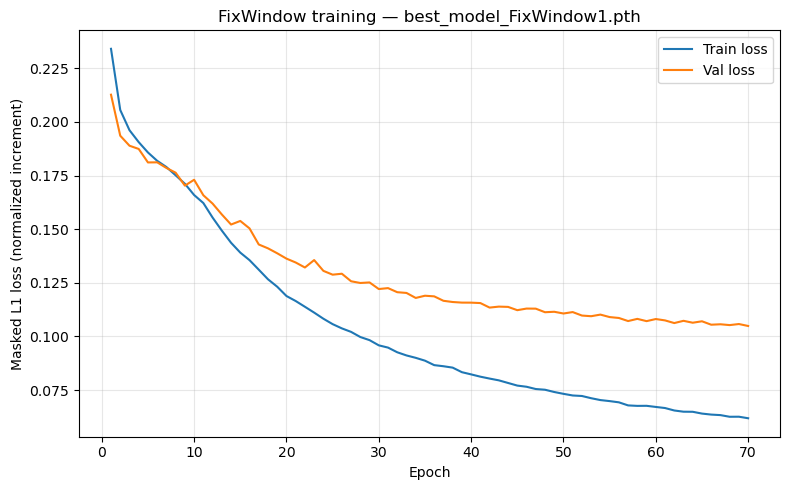

In [1]:
import json, re
import matplotlib.pyplot as plt

with open("autoReg_guiana_timeEmbed.ipynb") as f:
    nb = json.load(f)

text = ""
for cell in nb["cells"]:
    for out in cell.get("outputs", []):
        if out.get("output_type") == "stream":
            text += "".join(out.get("text", []))

epochs, train_loss, val_loss = [], [], []
for line in text.splitlines():
    m = re.match(
        r"Epoch (\d+) \| Train Loss: ([0-9.]+) \| Val Loss:([0-9.]+)", line
    )
    if m:
        epochs.append(int(m.group(1)))
        train_loss.append(float(m.group(2)))
        val_loss.append(float(m.group(3)))

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Train loss")
plt.plot(epochs, val_loss, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Masked L1 loss (normalized increment)")
plt.title("FixWindow training — best_model_FixWindow1.pth")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("PNG/training_loss_curve.png", dpi=150)
plt.show()